## Notebook 3 — Advanced Analytics: Forecasting, Clustering & Cohort Analysis

This notebook continues the workflow from Notebooks 1 and 2. It uses the cleaned transaction data and customer summary to perform three advanced analyses:

1. **Revenue forecasting** using an OLS linear trend fitted to a 3-month centred rolling average.
2. **Customer clustering** using K-Means on recency, order frequency, and revenue.
3. **Cohort retention analysis** to track the share of customers returning after their first purchase.

## 1. Import libraries and configure project paths

In [1]:
from pathlib import Path
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")

# Find the project root when Jupyter is launched from either the repo root
# or the Notebooks/ folder.
CURRENT_DIR = Path.cwd().resolve()
if (CURRENT_DIR / "Data").is_dir():
    ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "Data").is_dir():
    ROOT = CURRENT_DIR.parent
else:
    ROOT = CURRENT_DIR

DATA_DIR = ROOT / "Data"
OUTPUT_DIR = ROOT / "Outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLEAN_FILE = DATA_DIR / "online_retail_clean.csv"
CUST_FILE = DATA_DIR / "customer_summary.csv"
CLUS_OUT = DATA_DIR / "customer_clusters.csv"

print(f"Project root : {ROOT}")
print(f"Data folder  : {DATA_DIR}")
print(f"Output folder: {OUTPUT_DIR}")

Project root : C:\Users\FixTest\streaming_platform_customer_churn\retail-sales
Data folder  : C:\Users\FixTest\streaming_platform_customer_churn\retail-sales\Data
Output folder: C:\Users\FixTest\streaming_platform_customer_churn\retail-sales\Outputs


## 2. Load the cleaned transaction and customer datasets

In [2]:
# Notebook 1 must be completed before running this notebook.
missing_files = [path for path in (CLEAN_FILE, CUST_FILE) if not path.exists()]
if missing_files:
    missing_list = "\n".join(f"- {path}" for path in missing_files)
    raise FileNotFoundError(
        "Required input file(s) not found:\n"
        f"{missing_list}\n\n"
        "Run Notebook 1 first and confirm that its CSV outputs are in Data/."
    )

# Parse date columns during import so time-based analysis works correctly.
df = pd.read_csv(CLEAN_FILE, parse_dates=["invoicedate"])
df_cust = pd.read_csv(
    CUST_FILE,
    parse_dates=["first_purchase", "last_purchase"]
)

print(f"Transactions: {len(df):,} rows × {df.shape[1]} columns")
print(f"Customers   : {len(df_cust):,} rows × {df_cust.shape[1]} columns")

Transactions: 53,571 rows × 19 columns
Customers   : 5,535 rows × 13 columns


## 3. Preview the input datasets

In [3]:
print("Cleaned transaction data")
display(df.head())

print("Customer summary data")
display(df_cust.head())

Cleaned transaction data


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,revenue,year,month,month_name,quarter,week,day_of_week,is_weekend,hour,country_clean,order_id
0,536366,85123A,White Hanging Heart T-Light Holder,2,2009-12-01 12:07:00,2.55,15238,United Kingdom,5.10,2009,12,Dec,Q4,49,1,False,12,United Kingdom,536366
1,536367,47566,Party Bunting,3,2009-12-01 11:15:00,4.95,12253,United Kingdom,14.85,2009,12,Dec,Q4,49,1,False,11,United Kingdom,536367
2,536367,22752,Set Of 3 Cake Tins Pantry Design,4,2009-12-01 11:15:00,4.65,12253,United Kingdom,18.60,2009,12,Dec,Q4,49,1,False,11,United Kingdom,536367
3,536367,22469,Heart Of Wicker Small,12,2009-12-01 11:15:00,1.65,12253,United Kingdom,19.80,2009,12,Dec,Q4,49,1,False,11,United Kingdom,536367
4,536367,84029G,Knitted Union Flag Hot Water Bottle,8,2009-12-01 11:15:00,3.39,12253,United Kingdom,27.12,2009,12,Dec,Q4,49,1,False,11,United Kingdom,536367


Customer summary data


,customer_id,total_revenue,total_orders,total_items,first_purchase,last_purchase,avg_order_value,recency_days,r_score,f_score,m_score,rfm_score,segment
0,10000,2.50,1,2,2010-01-26 01:33:00,2010-01-26 01:33:00,2.50,683,1,1,1,3,Lost
1,10001,142.40,2,27,2010-01-11 04:52:00,2010-02-12 10:48:00,71.20,666,1,1,4,6,At Risk
2,10002,272.93,4,61,2010-05-12 09:20:00,2011-08-24 15:41:00,68.23,108,3,4,5,12,Loyal Customers
3,10003,509.47,4,178,2009-12-04 11:19:00,2011-02-25 10:58:00,127.37,288,2,4,5,11,Loyal Customers
4,10004,157.49,3,55,2010-09-01 11:51:00,2011-09-06 13:02:00,52.50,95,4,3,4,11,Loyal Customers


In [4]:
print("Transaction date range:")
print(f"{df['invoicedate'].min()} → {df['invoicedate'].max()}")

print("\nCustomer summary columns:")
print(df_cust.columns.tolist())

Transaction date range:
2009-12-01 06:24:00 → 2011-12-09 16:11:00

Customer summary columns:
['customer_id', 'total_revenue', 'total_orders', 'total_items', 'first_purchase', 'last_purchase', 'avg_order_value', 'recency_days', 'r_score', 'f_score', 'm_score', 'rfm_score', 'segment']


## 4. Set chart styling and create a save/display helper

In [5]:
# Design tokens retained from the original analysis script.
ACCENT = "#E94560"
BLUE = "#0F3460"
BG = "#FAFAFA"
DPI = 180  # Export resolution for saved chart images.

CLUSTER_COLORS = {
    "High-Value Active": "#2ECC71",
    "High-Value Dormant": "#E94560",
    "Low-Value Active": "#3498DB",
    "Low-Value Dormant": "#AAAAAA",
}

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": BG,
    "axes.edgecolor": "#CCCCCC",
    "grid.color": "#E5E5E5",
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print(f"Charts will be saved to: {OUTPUT_DIR}")

Charts will be saved to: C:\Users\FixTest\streaming_platform_customer_churn\retail-sales\Outputs


In [7]:
def _save(fig: plt.Figure, name: str, insight: str) -> None:
    """Save a figure, display it in the notebook, and print its insight note."""
    path = OUTPUT_DIR / name
    fig.savefig(path, dpi=DPI, bbox_inches="tight", facecolor=BG)
    width, height = fig.get_size_inches()

    # Display before closing so the chart appears below the cell in Jupyter.
    display(fig)
    plt.close(fig)

    print(f"  ✓ {name:<50} ({int(width * DPI)}×{int(height * DPI)} px)")
    print(f"    {insight}\n")

## 5. Section A — Revenue forecasting

### Method: OLS linear trend on a 3-month centred rolling average

The original analysis uses a simple linear trend rather than ARIMA or Prophet. Its stated rationale is that the 24 monthly observations are limited for more parameter-intensive forecasting without significant tuning, while a linear trend on smoothed data is straightforward to explain to business stakeholders.

**Workflow**
1. Aggregate transaction revenue into monthly totals.
2. Calculate a 3-month centred rolling average to reduce noise.
3. Fit a first-degree polynomial (linear OLS trend) to the smoothed series.
4. Extrapolate the trend for the next three months.
5. Calculate an 80% prediction interval using ±1.28 times the residual standard deviation.

In [8]:
def revenue_forecast(df: pd.DataFrame, n_ahead: int = 3) -> None:
    """
    Produce a 3-month revenue forecast with an 80% prediction interval.

    Steps
    ─────
    1. Aggregate daily transactions to monthly totals.
    2. Apply a 3-month centred rolling average to reduce noise.
    3. Fit OLS linear regression (slope, intercept) on smoothed series.
    4. Extrapolate n_ahead periods beyond the last observed month.
    5. Compute prediction interval from residual standard deviation.
    """
    print("── Section A: Revenue Forecasting ──────────────────────")

    monthly = (
        df.groupby(["year", "month"])["revenue"]
          .sum().reset_index()
          .sort_values(["year", "month"]).reset_index(drop=True)
    )
    monthly["idx"]     = np.arange(len(monthly))
    monthly["rolling"] = monthly["revenue"].rolling(3, center=True).mean()
    fit = monthly.dropna(subset=["rolling"]).copy()

    # OLS fit
    x = fit["idx"].values.astype(float)
    y = fit["rolling"].values
    slope, intercept = np.polyfit(x, y, deg=1)
    y_hat   = slope * x + intercept
    resid   = y - y_hat
    pi_80   = 1.28 * resid.std()          # 80% PI half-width

    # Forecast
    last_idx    = monthly["idx"].max()
    future_idx  = np.arange(last_idx + 1, last_idx + n_ahead + 1)
    forecast    = slope * future_idx + intercept

    # Print forecast table
    print(f"\n  OLS trend: slope = £{slope:+,.0f}/month")
    print(f"  Residual σ = £{resid.std():,.0f}  |  80% PI half-width = £{pi_80:,.0f}\n")
    print(f"  {'Period':<12}  {'Forecast':>12}  {'PI Lower':>12}  {'PI Upper':>12}")
    print(f"  {'-'*50}")
    for i, (idx, rev) in enumerate(zip(future_idx, forecast), 1):
        print(f"  Month +{i:<5}  £{rev:>10,.0f}  £{(rev-pi_80):>10,.0f}  £{(rev+pi_80):>10,.0f}")
    print()

    # Plot
    fig, ax = plt.subplots(figsize=(16, 5))
    ax.plot(monthly["idx"], monthly["revenue"] / 1e6,
            color="#BBBBBB", lw=1.2, alpha=0.8, label="Actual Monthly Revenue")
    ax.plot(fit["idx"], fit["rolling"] / 1e6,
            color=BLUE, lw=2.2, label="3-Month Rolling Average")
    ax.plot(future_idx, forecast / 1e6,
            color=ACCENT, lw=2.2, ls="--", label=f"Forecast (next {n_ahead} months)")
    ax.fill_between(
        future_idx,
        (forecast - pi_80) / 1e6,
        (forecast + pi_80) / 1e6,
        color=ACCENT, alpha=0.15, label="80% Prediction Interval",
    )
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"£{v:.2f}M"))
    ax.set_xlabel("Period (month index)", fontsize=11)
    ax.set_ylabel("Revenue (£M)", fontsize=11)
    ax.set_title(f"Revenue Forecast — {n_ahead}-Month Outlook with Prediction Interval",
                 fontsize=15, fontweight="bold")
    ax.legend(fontsize=9)
    ax.grid(axis="y", alpha=0.4)

    _save(fig, "10_revenue_forecast.png",
          "Linear trend projects continued growth. Wide PI captures Q4 volatility. "
          "Use as a planning baseline, not a guarantee.")

# The function also displays the forecast chart and prints the forecast table.

── Section A: Revenue Forecasting ──────────────────────

  OLS trend: slope = £+73/month
  Residual σ = £5,066  |  80% PI half-width = £6,485

  Period            Forecast      PI Lower      PI Upper
  --------------------------------------------------
  Month +1      £    34,561  £    28,076  £    41,046
  Month +2      £    34,635  £    28,150  £    41,120
  Month +3      £    34,708  £    28,223  £    41,193



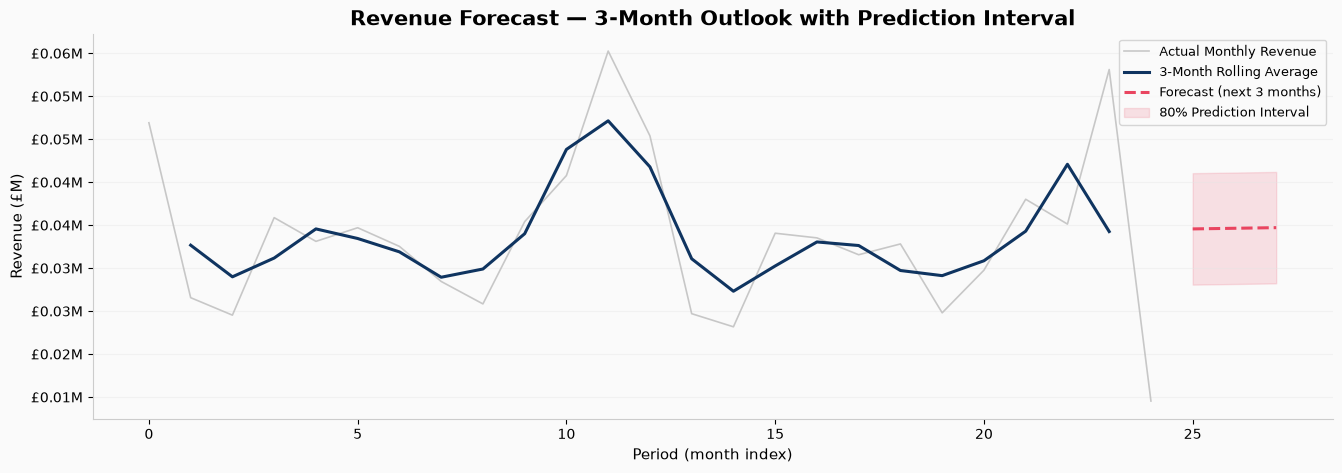

  ✓ 10_revenue_forecast.png                            (2880×900 px)
    Linear trend projects continued growth. Wide PI captures Q4 volatility. Use as a planning baseline, not a guarantee.



In [9]:
# Generate the next three months of revenue forecasts.
revenue_forecast(df, n_ahead=3)

## 6. Section B — K-Means customer clustering

The clustering model uses three customer-level features:

- `recency_days`: days since the customer's last purchase.
- `total_orders`: number of distinct orders.
- `total_revenue`: lifetime revenue.

The features are standardised with `StandardScaler` before K-Means is fitted. The Elbow method (inertia) and Silhouette score are calculated for candidate cluster counts from 2 through 9. The source script reports the best Silhouette value, displays K=4 as the selected business grouping, and returns 4 to keep the business labels consistent.

In [10]:
def _scale(df_cust: pd.DataFrame, features: list) -> tuple:
    scaler   = StandardScaler()
    X_scaled = scaler.fit_transform(df_cust[features])
    return X_scaled, scaler

In [11]:
def elbow_silhouette(df_cust: pd.DataFrame, K_max: int = 9) -> int:
    """
    Plot Elbow (inertia) and Silhouette curves to determine optimal K.
    Returns the recommended K (highest silhouette score).
    """
    print("── Section B: K-Means Cluster Validation ────────────────")

    features  = ["recency_days", "total_orders", "total_revenue"]
    X, _      = _scale(df_cust, features)
    K_range   = range(2, K_max + 1)
    inertias  = []
    sil_scores = []

    for k in K_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        km.fit(X)
        inertias.append(km.inertia_)
        sil_scores.append(silhouette_score(X, km.labels_))
        print(f"  K={k}  Inertia={km.inertia_:>10,.0f}  Silhouette={sil_scores[-1]:.4f}")

    best_k = list(K_range)[sil_scores.index(max(sil_scores))]
    print(f"\n  → Recommended K based on silhouette: {best_k}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(list(K_range), inertias, marker="o", color=BLUE, lw=2.2)
    ax1.axvline(4, color=ACCENT, ls="--", lw=1.8, label="Selected K=4")
    ax1.set_title("Elbow Method — Within-Cluster Inertia", fontweight="bold", fontsize=13)
    ax1.set_xlabel("Number of Clusters (K)", fontsize=11)
    ax1.set_ylabel("Inertia", fontsize=11)
    ax1.legend(fontsize=9)
    ax1.grid(axis="y", alpha=0.4)

    ax2.plot(list(K_range), sil_scores, marker="o", color=ACCENT, lw=2.2)
    ax2.axvline(4, color=BLUE, ls="--", lw=1.8, label="Selected K=4")
    ax2.set_title("Silhouette Score — Cluster Separation Quality",
                  fontweight="bold", fontsize=13)
    ax2.set_xlabel("Number of Clusters (K)", fontsize=11)
    ax2.set_ylabel("Silhouette Score (higher = better)", fontsize=11)
    ax2.legend(fontsize=9)
    ax2.grid(axis="y", alpha=0.4)

    fig.suptitle("Optimal K Validation — K=4 Selected", fontsize=15, fontweight="bold")
    plt.tight_layout()
    _save(fig, "11_elbow_and_silhouette.png",
          "K=4 is the elbow point with near-peak silhouette — "
          "adding more clusters yields diminishing separation quality.")

    return 4

# Returns 4 for consistent downstream business labels.

── Section B: K-Means Cluster Validation ────────────────
  K=2  Inertia=    10,327  Silhouette=0.3375
  K=3  Inertia=     7,149  Silhouette=0.3452
  K=4  Inertia=     5,767  Silhouette=0.3195
  K=5  Inertia=     4,975  Silhouette=0.3372
  K=6  Inertia=     4,406  Silhouette=0.3045
  K=7  Inertia=     3,887  Silhouette=0.3114
  K=8  Inertia=     3,466  Silhouette=0.3078
  K=9  Inertia=     3,154  Silhouette=0.3099

  → Recommended K based on silhouette: 3


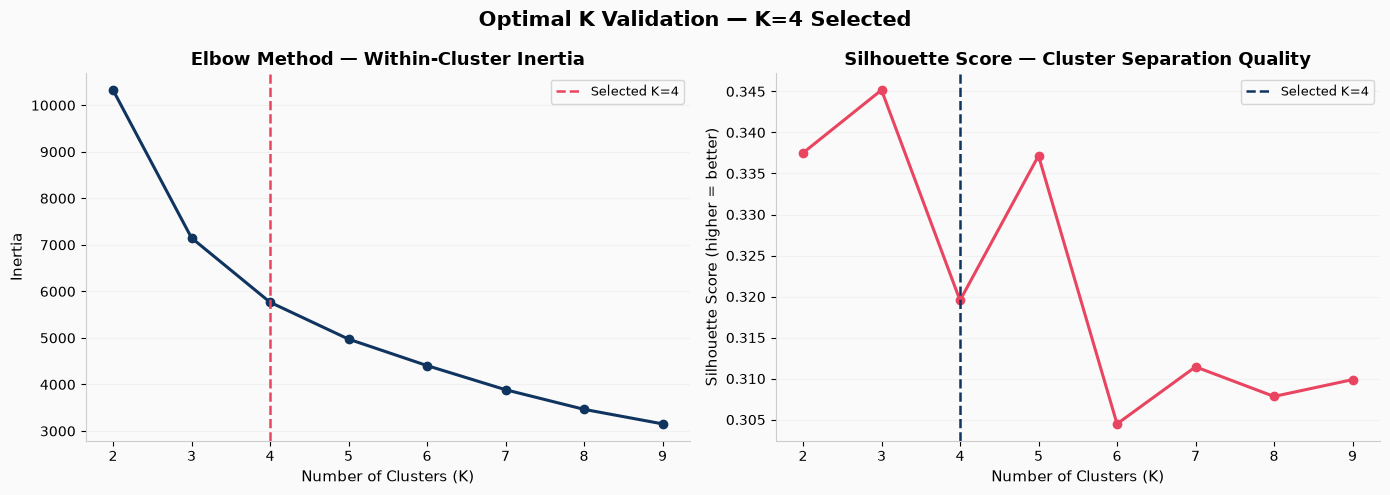

  ✓ 11_elbow_and_silhouette.png                        (2520×900 px)
    K=4 is the elbow point with near-peak silhouette — adding more clusters yields diminishing separation quality.

Selected number of clusters: 4


In [12]:
# Compare candidate cluster counts and display the validation plots.
selected_k = elbow_silhouette(df_cust, K_max=9)
print(f"Selected number of clusters: {selected_k}")

### 6.1 Fit K-Means and interpret customer clusters

After fitting K-Means, the cluster centroids are converted back to the original feature scales. The source logic labels each cluster by comparing centroid revenue and recency against their respective medians:

| Cluster label | Revenue level | Recency level |
|---|---|---|
| High-Value Active | Above median | Below median |
| High-Value Dormant | Above median | Above median |
| Low-Value Active | Below median | Below median |
| Low-Value Dormant | Below median | Above median |

In [13]:
def fit_clusters(df_cust: pd.DataFrame, n_clusters: int = 4) -> pd.DataFrame:
    """
    Fit K-Means on [recency_days, total_orders, total_revenue] and assign
    human-readable cluster labels based on centroid interpretation.

    Label Logic
    ───────────
    High-Value Active  : above-median revenue + below-median recency
    High-Value Dormant : above-median revenue + above-median recency
    Low-Value Active   : below-median revenue + below-median recency
    Low-Value Dormant  : below-median revenue + above-median recency
    """
    print(f"\n── Fitting K-Means (K={n_clusters}) ─────────────────────────")

    features  = ["recency_days", "total_orders", "total_revenue"]
    X, scaler = _scale(df_cust, features)

    km = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    df_cust = df_cust.copy()
    df_cust["cluster"] = km.fit_predict(X)

    # Interpret centroids (inverse-transform to original scale)
    centroids = pd.DataFrame(
        scaler.inverse_transform(km.cluster_centers_),
        columns=features,
    )
    centroids["cluster"] = range(n_clusters)

    print("\n  Cluster centroids (original scale):")
    print(centroids.to_string(index=False))

    med_rev = centroids["total_revenue"].median()
    med_rec = centroids["recency_days"].median()
    label_map = {}
    for _, row in centroids.iterrows():
        hv = row["total_revenue"] > med_rev
        lr = row["recency_days"]  < med_rec
        if   hv and lr:  label_map[int(row["cluster"])] = "High-Value Active"
        elif hv and not lr: label_map[int(row["cluster"])] = "High-Value Dormant"
        elif lr:            label_map[int(row["cluster"])] = "Low-Value Active"
        else:               label_map[int(row["cluster"])] = "Low-Value Dormant"

    df_cust["cluster_label"] = df_cust["cluster"].map(label_map)

    print("\n  Cluster summary:")
    print(f"  {'Label':<25}  {'Count':>6}  {'Avg Revenue':>12}  {'Avg Recency':>12}")
    print(f"  {'-'*60}")
    for label, grp in df_cust.groupby("cluster_label"):
        print(f"  {label:<25}  {len(grp):>6,}  "
              f"£{grp['total_revenue'].mean():>10,.0f}  "
              f"{grp['recency_days'].mean():>10.0f} days")

    return df_cust

In [14]:
# Fit the four customer clusters.
df_clustered = fit_clusters(df_cust, n_clusters=selected_k)

# Save the customer-level cluster assignments.
df_clustered.to_csv(CLUS_OUT, index=False)
print(f"\nCluster file saved: {CLUS_OUT}")

# Review the number of customers and average metrics in each segment.
cluster_summary = (
    df_clustered.groupby("cluster_label")
    .agg(
        customers=("customer_id", "count"),
        avg_revenue=("total_revenue", "mean"),
        avg_orders=("total_orders", "mean"),
        avg_recency_days=("recency_days", "mean"),
        avg_order_value=("avg_order_value", "mean"),
    )
    .sort_values("avg_revenue", ascending=False)
    .reset_index()
)
display(cluster_summary.round(2))


── Fitting K-Means (K=4) ─────────────────────────

  Cluster centroids (original scale):
 recency_days  total_orders  total_revenue  cluster
   109.095090      4.293350     178.874525        0
   121.645293      2.167939      78.576606        1
   463.558036      1.762649      83.005119        2
   127.173420      4.967585     464.668882        3

  Cluster summary:
  Label                       Count   Avg Revenue   Avg Recency
  ------------------------------------------------------------
  High-Value Active           1,605  £       179         109 days
  High-Value Dormant            619  £       464         127 days
  Low-Value Active            1,967  £        79         122 days
  Low-Value Dormant           1,344  £        83         464 days

Cluster file saved: C:\Users\FixTest\streaming_platform_customer_churn\retail-sales\Data\customer_clusters.csv


,cluster_label,customers,avg_revenue,avg_orders,avg_recency_days,avg_order_value
0,High-Value Dormant,619,464.24,4.96,127.34,106.64
1,High-Value Active,1605,178.58,4.30,109.03,44.88
2,Low-Value Dormant,1344,83.01,1.76,463.56,48.52
3,Low-Value Active,1967,78.76,2.17,121.62,39.06


### 6.2 Visualise customer clusters: recency vs lifetime revenue

In [15]:
def chart_cluster_scatter(df_cust: pd.DataFrame) -> None:
    fig, ax = plt.subplots(figsize=(11, 7))
    for label, grp in df_cust.groupby("cluster_label"):
        ax.scatter(grp["recency_days"], grp["total_revenue"],
                   label=label, alpha=0.55, s=22,
                   color=CLUSTER_COLORS.get(label, "#555"), edgecolors="none")

    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"£{v:,.0f}"))
    ax.set_xlabel("Recency — Days Since Last Purchase", fontsize=11)
    ax.set_ylabel("Lifetime Revenue (£)", fontsize=11)
    ax.set_title("Customer Clusters — Recency vs Lifetime Revenue",
                 fontsize=15, fontweight="bold")
    ax.legend(fontsize=10, framealpha=0.85, title="Cluster", title_fontsize=10)
    ax.grid(alpha=0.4)

    _save(fig, "12_cluster_scatter.png",
          "High-Value Dormant customers spent heavily but haven't returned — "
          "highest win-back ROI. Target with a 15% discount win-back sequence.")

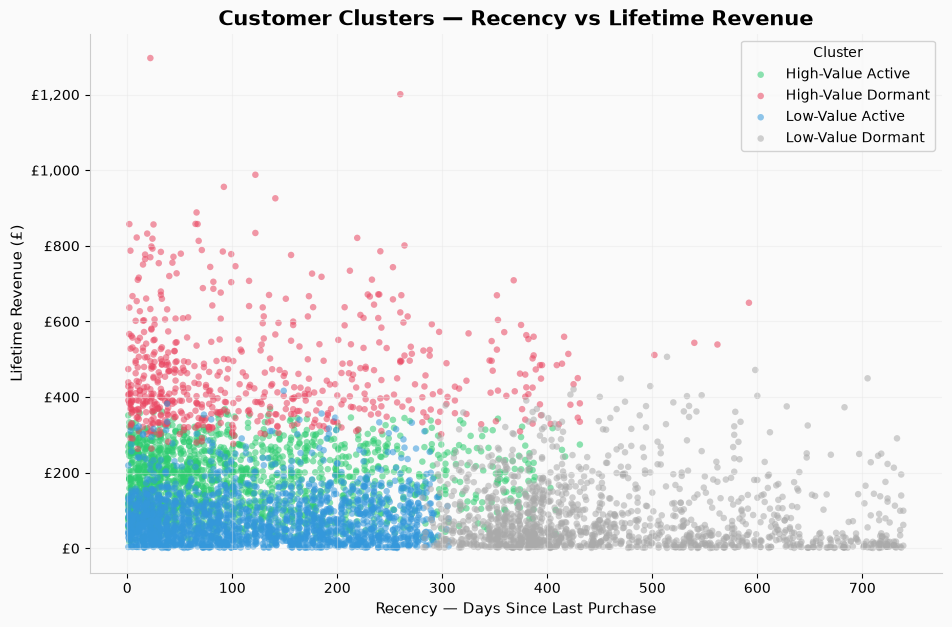

  ✓ 12_cluster_scatter.png                             (1980×1260 px)
    High-Value Dormant customers spent heavily but haven't returned — highest win-back ROI. Target with a 15% discount win-back sequence.



In [16]:
chart_cluster_scatter(df_clustered)

### 6.3 Compare average cluster profiles

In [17]:
def chart_cluster_profiles(df_cust: pd.DataFrame) -> None:
    """
    Radar / bar profile chart showing each cluster's average metrics.
    Uses a 4-panel bar layout (more readable than radar at print size).
    """
    metrics = {
        "Avg Revenue (£)":       "total_revenue",
        "Avg Orders":            "total_orders",
        "Avg Recency (days)":    "recency_days",
        "Avg Order Value (£)":   "avg_order_value",
    }
    labels = list(CLUSTER_COLORS.keys())
    colors = list(CLUSTER_COLORS.values())

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    fig.suptitle("Cluster Profiles — Average Metrics per Segment",
                 fontsize=16, fontweight="bold")

    for ax, (metric_label, col) in zip(axes, metrics.items()):
        vals = [df_cust.loc[df_cust["cluster_label"] == lbl, col].mean()
                for lbl in labels]
        bars = ax.bar(labels, vals, color=colors, edgecolor="white")
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.02,
                    f"{val:,.0f}", ha="center", va="bottom", fontsize=8.5)
        ax.set_title(metric_label, fontweight="bold", fontsize=11)
        ax.tick_params(axis="x", rotation=20, labelsize=8)
        ax.grid(axis="y", alpha=0.4)

    plt.tight_layout()
    _save(fig, "13_cluster_profiles.png",
          "High-Value Active customers have both high revenue and low recency — "
          "the Champions tier that deserves a dedicated loyalty programme.")

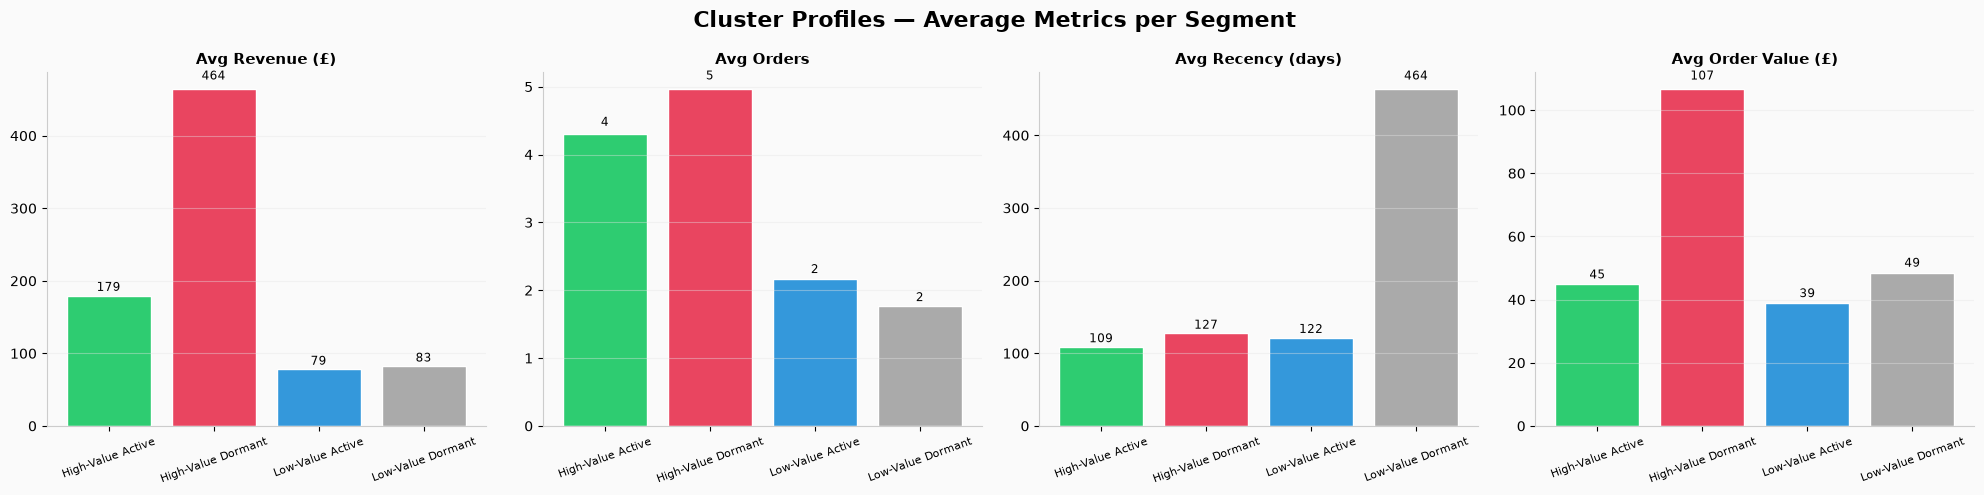

  ✓ 13_cluster_profiles.png                            (3600×900 px)
    High-Value Active customers have both high revenue and low recency — the Champions tier that deserves a dedicated loyalty programme.



In [18]:
chart_cluster_profiles(df_clustered)

## 7. Section C — Cohort retention analysis

A cohort is defined by the month in which a customer first purchased. The analysis calculates the month offset between each transaction month and the customer's first-purchase month, then measures the percentage of each acquisition cohort that returned in subsequent months.

The resulting heatmap shows retention from month 0 through month 11 (where data is available). The cell also prints average Month-2 and Month-12 retention when those offsets are present.

In [19]:
def chart_cohort_retention(df: pd.DataFrame) -> None:
    """
    Build a cohort retention matrix showing what % of customers who
    first purchased in month M returned in months M+1 through M+11.

    This is the same calculation as SQL Q11 but executed in Python
    so the heatmap visualisation can be included in the outputs folder.
    """
    print("── Section C: Cohort Retention Analysis ─────────────────")

    df2 = df.copy()
    df2["order_month"]  = df2["invoicedate"].dt.to_period("M")
    first_buy = (
        df2.groupby("customer_id")["order_month"].min().rename("cohort_month")
    )
    df2 = df2.join(first_buy, on="customer_id")
    df2["month_offset"] = (
        df2["order_month"].astype(int) - df2["cohort_month"].astype(int)
    )

    cohort_size = (
        df2[df2["month_offset"] == 0]
          .groupby("cohort_month")["customer_id"].nunique()
          .rename("cohort_size")
    )

    retention = (
        df2[df2["month_offset"] >= 0]
          .groupby(["cohort_month", "month_offset"])["customer_id"]
          .nunique()
          .reset_index()
          .join(cohort_size, on="cohort_month")
    )
    retention["retention_rate"] = retention["customer_id"] / retention["cohort_size"]

    # Pivot to matrix
    pivot = (
        retention[retention["month_offset"] <= 11]
          .pivot(index="cohort_month", columns="month_offset", values="retention_rate")
    )
    pivot.index = pivot.index.astype(str)

    # Print headline stats
    if 1 in pivot.columns:
        m2_avg = pivot[1].dropna().mean()
        print(f"\n  Month-2 average retention : {m2_avg:.1%}")
    if 11 in pivot.columns:
        m12_avg = pivot[11].dropna().mean()
        print(f"  Month-12 average retention: {m12_avg:.1%}\n")

    fig, ax = plt.subplots(figsize=(16, 8))
    sns.heatmap(
        pivot,
        ax=ax,
        fmt=".0%",
        annot=True,
        cmap="RdYlGn",
        vmin=0, vmax=1,
        linewidths=0.5,
        cbar_kws={"label": "Retention Rate", "shrink": 0.6},
        annot_kws={"size": 8},
    )
    ax.set_title("Customer Cohort Retention — % Returning Each Month",
                 fontsize=15, fontweight="bold")
    ax.set_xlabel("Months After First Purchase", fontsize=11)
    ax.set_ylabel("Acquisition Cohort (Month)", fontsize=11)

    _save(fig, "14_cohort_retention.png",
          "Month-2 retention is below 35% across all cohorts. "
          "This is structural, not seasonal — a Day-7 + Day-30 email sequence "
          "is the recommended fix to close the gap.")

── Section C: Cohort Retention Analysis ─────────────────

  Month-2 average retention : 11.1%
  Month-12 average retention: 11.2%



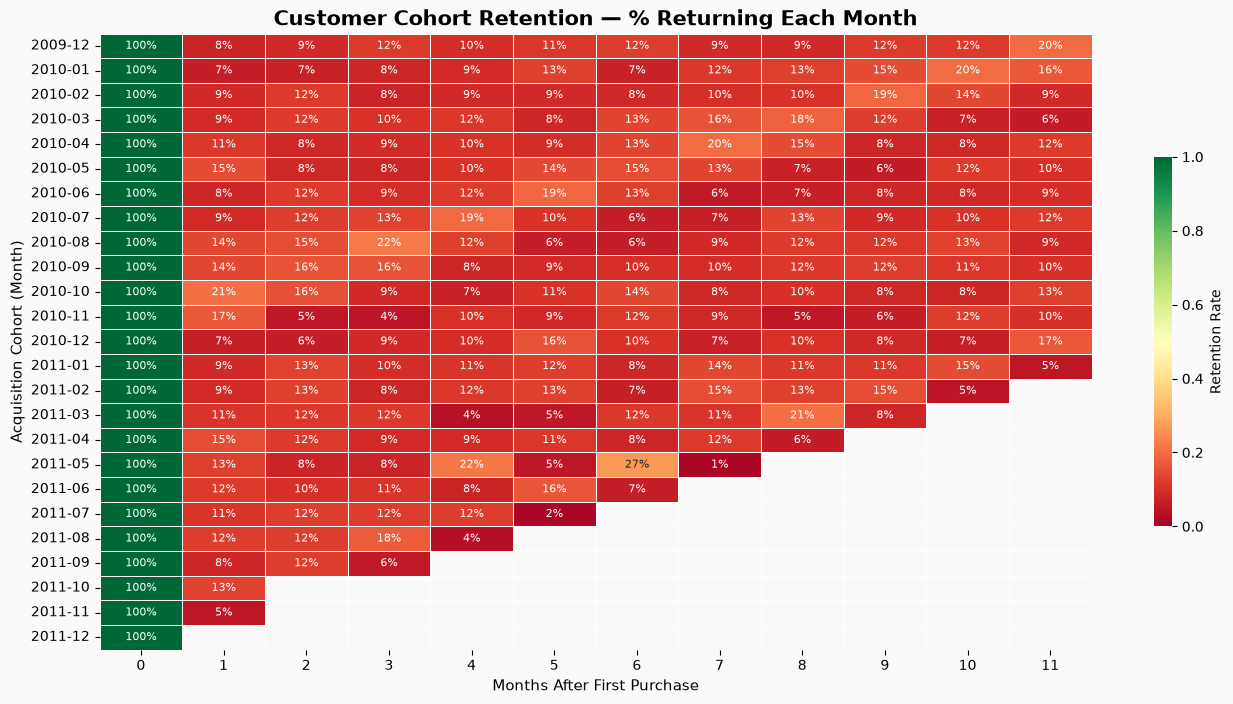

  ✓ 14_cohort_retention.png                            (2880×1440 px)
    Month-2 retention is below 35% across all cohorts. This is structural, not seasonal — a Day-7 + Day-30 email sequence is the recommended fix to close the gap.



In [20]:
chart_cohort_retention(df)

## 8. Review generated files

In [21]:
# List the advanced-analysis charts generated in Outputs/.
chart_names = [
    "10_revenue_forecast.png",
    "11_elbow_and_silhouette.png",
    "12_cluster_scatter.png",
    "13_cluster_profiles.png",
    "14_cohort_retention.png",
]

chart_summary = pd.DataFrame({
    "chart_file": chart_names,
    "exists": [(OUTPUT_DIR / name).exists() for name in chart_names],
    "size_kb": [
        round((OUTPUT_DIR / name).stat().st_size / 1024, 1)
        if (OUTPUT_DIR / name).exists() else np.nan
        for name in chart_names
    ],
})
display(chart_summary)

print(f"\nCluster CSV exists: {CLUS_OUT.exists()}")
if CLUS_OUT.exists():
    print(f"Cluster CSV size: {CLUS_OUT.stat().st_size / 1024:.1f} KB")

,chart_file,exists,size_kb
0,10_revenue_forecast.png,True,140.4
1,11_elbow_and_silhouette.png,True,134.9
2,12_cluster_scatter.png,True,485.8
3,13_cluster_profiles.png,True,132.4
4,14_cohort_retention.png,True,345.5



Cluster CSV exists: True
Cluster CSV size: 595.5 KB
